# Crop Price Prediction - Leakage Fixed

**Correction:** Previous `Modal_Price_Roll7` included the current day's price (Data Leakage).
In this notebook, we recalculate rolling averages using only **PAST** data.

- **Feature Engineering**: 
  - `Roll7` = Mean of `Modal_Price` from t-7 to t-1
  - `Roll30` = Mean of `Modal_Price` from t-30 to t-1

Goal: Achieve realistic and high predictive accuracy.

In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [7]:
# Load Data
df = pd.read_csv('final_forecasting_dataset.csv')

# --- FIX DATA LEAKAGE ---
# Calculate correct Rolling Averages (Shift first, then Roll)
df['Modal_Price_Corrected_Roll7'] = df['Modal_Price'].shift(1).rolling(window=7).mean()
df['Modal_Price_Corrected_Roll30'] = df['Modal_Price'].shift(1).rolling(window=30).mean()

# Drop original leaked columns if they exist (just to be safe we don't use them)
# We will simply not select them in the features list

# Drop NaNs created by Shift+Roll
df_clean = df.dropna()

# Define Features (Using CORRECTED Rolling features)
features = [
    'Season_Num', 'Rainfall_mm', 'Temp_C', 
    'Rainfall_Lag7', 'Temp_Lag7', 'Festival_Flag',
    'Modal_Price_Lag7', 'Modal_Price_Lag30', 
    'Modal_Price_Corrected_Roll7', 'Modal_Price_Corrected_Roll30',
    'Price_Momentum', 'Fourier_sin', 'Fourier_cos'
]

X = df_clean[features]
y = df_clean['Modal_Price']

# Split Data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [8]:
# Train Random Forest
rf = RandomForestRegressor(n_estimators=200, max_depth=None, min_samples_split=2, random_state=42)
rf.fit(X_train, y_train)

RandomForestRegressor(n_estimators=200, random_state=42)

In [9]:
# Evaluate
y_pred = rf.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("--- Corrected Random Forest ---")
print(f"MAE:  {mae:.2f}")
print(f"MSE:  {mse:.2f}")
print(f"RMSE: {rmse:.2f}")
print(f"R2:   {r2:.4f}")

--- Corrected Random Forest ---
MAE:  101.15
MSE:  45609.58
RMSE: 213.56
R2:   0.9771


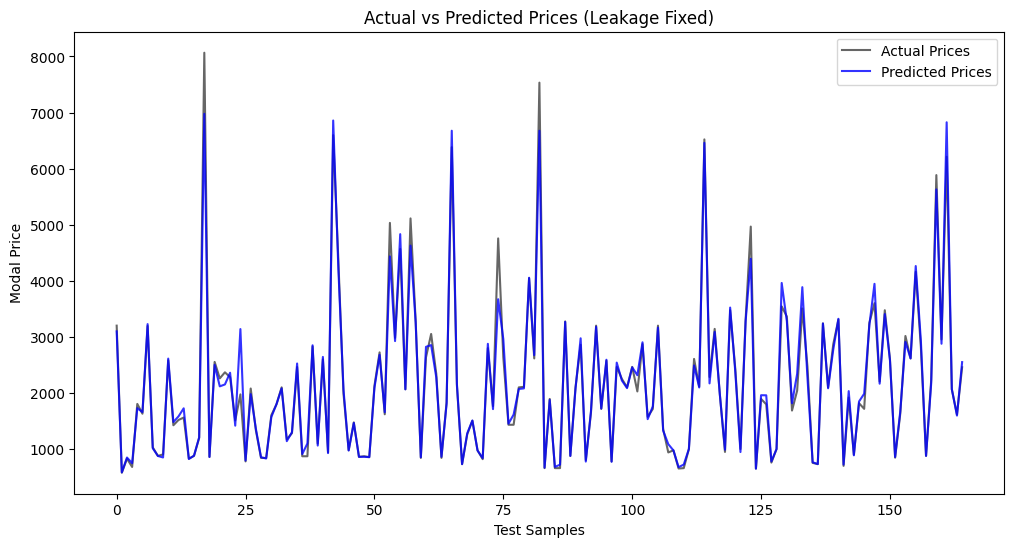

In [10]:
# Visualization
plt.figure(figsize=(12, 6))
plt.plot(y_test.values, label='Actual Prices', color='black', alpha=0.6)
plt.plot(y_pred, label='Predicted Prices', color='blue', alpha=0.8)
plt.title("Actual vs Predicted Prices (Leakage Fixed)")
plt.xlabel("Test Samples")
plt.ylabel("Modal Price")
plt.legend()
plt.show()